
## A2.1(a) Gillespie Simulation of the Stochastic SIS Model

The SIS model describes a population of size $N$ in which individuals are either susceptible or infectious. Infected individuals can transmit the disease to susceptible individuals, while infectious individuals can recover and become susceptible again.

Let $x$ denote the number of infectious individuals. The model has two possible events:

1. **Infection:** An infection occurs at rate
   $$w_1(x) = \frac{\beta x(N-x)}{N},$$
   increasing the number of infectious individuals by one.

2. **Recovery:** A recovery occurs at rate
   $$w_2(x) = \alpha x,$$
   decreasing the number of infectious individuals by one.

The Gillespie algorithm calculates the total event rate $W(x)=w_1(x)+w_2(x)$, samples the waiting time from an exponential distribution with mean $1/W(x)$, and selects the next event with probability proportional to its rate.

The implementation below separates event rate functions and state variations from the simulation algorithm, allowing the same function to be reused for other stochastic models.

In [17]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# Event rate functions:
def infection_rate(x, N, alpha, beta):
    return beta * x * (N - x) / N


def recovery_rate(x, N, alpha, beta):
    return alpha * x


# Event rates and corresponding state variations:
sis_rates = [infection_rate, recovery_rate]
sis_deltas = [1, -1]


# Generic Gillespie simulation
def gillespie(x0, T, rng, rates, deltas, params):
    t = 0.0
    x = x0

    times = [t]
    states = [x]

    while t < T:
        # Calculate the rate of each possible event
        event_rates = np.array([
            rate(x, **params) for rate in rates
        ], dtype=float)

        total_rate = np.sum(event_rates)

        # Stop if no events are possible
        if total_rate <= 0:
            break

        # Sample the waiting time until the next event
        dt = rng.exponential(scale=1.0 / total_rate)

        # Stop if the next event occurs beyond the time horizon
        if t + dt > T:
            break

        # Select an event with probability proportional to its rate
        probabilities = event_rates / total_rate
        event = rng.choice(len(rates), p=probabilities)

        # Update the time and state:
        t += dt
        x += deltas[event]

        times.append(t)
        states.append(x)

    return np.array(times), np.array(states)



## A2.1(b) Stochastic Trajectories for $N=500$

We simulate 50 independent stochastic SIS trajectories using Gillespie's algorithm with the parameters

$$
N=500,\quad \alpha=1,\quad \beta=1.5,\quad
x(0)=N/10=50,\quad T=20.
$$

We compare these trajectories with the deterministic solution of

$$
\frac{di}{dt}
=\frac{\beta i(N-i)}{N}-\alpha i,
\qquad i(0)=50.
$$

The stochastic trajectories are displayed using a step plot, while the deterministic solution is shown as a continuous curve.

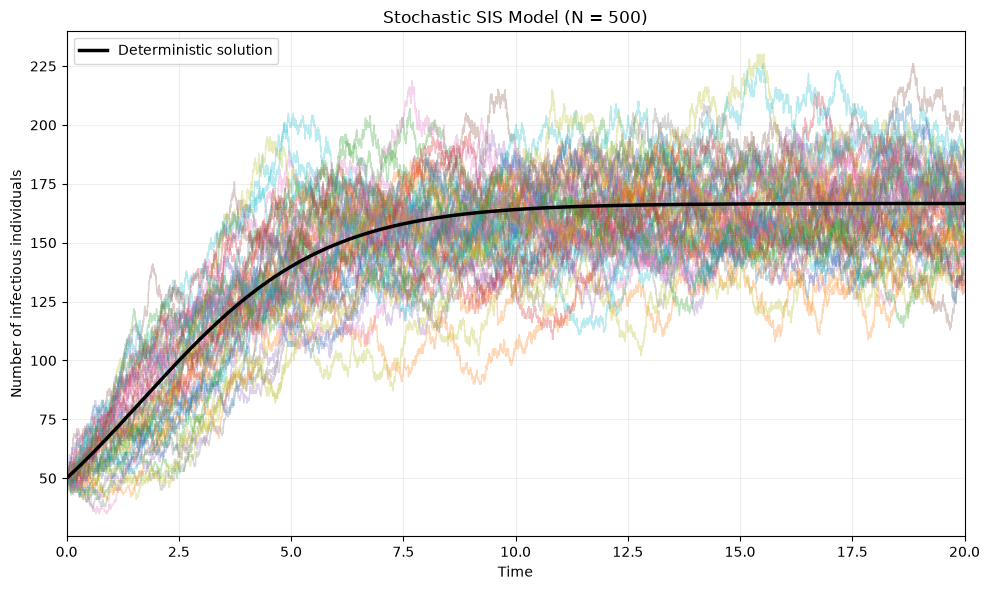

In [18]:

# Model parameters:
N = 500
alpha = 1.0
beta = 1.5
T = 20.0
x0 = N // 10
n_trajectories = 50

params = {
    "N": N,
    "alpha": alpha,
    "beta": beta
}

# Generate 50 stochastic trajectories:
rng = np.random.default_rng(42)

trajectories = [
    gillespie(
        x0=x0,
        T=T,
        rng=rng,
        rates=sis_rates,
        deltas=sis_deltas,
        params=params
    )
    for _ in range(n_trajectories)
]


# Deterministic SIS model:
def sis_ode(t, i):
    return beta * i * (N - i) / N - alpha * i


t_eval = np.linspace(0, T, 1000)

solution = solve_ivp(
    sis_ode,
    (0, T),
    [x0],
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)


# Plot the stochastic and deterministic trajectories:
fig, ax = plt.subplots(figsize=(10, 6))

for times, states in trajectories:
    ax.step(
        times,
        states,
        where="post",
        alpha=0.3,
        linewidth=1
    )

ax.plot(
    solution.t,
    solution.y[0],
    color="black",
    linewidth=2.5,
    label="Deterministic solution"
)

ax.set_xlabel("Time")
ax.set_ylabel("Number of infectious individuals")
ax.set_title("Stochastic SIS Model (N = 500)")
ax.set_xlim(0, T)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Discussion

The stochastic trajectories fluctuate around the deterministic solution due to the randomness of infection and recovery events. The deterministic solution shows the overall trend of the infectious population, while individual stochastic trajectories may deviate from it. The deterministic solution approaches a positive equilibrium of $N(1-\alpha/\beta) = 166.67$ infectious individuals. In contrast, stochastic trajectories may eventually reach extinction if the number of infectious individuals becomes zero. Since zero is an absorbing state, no further infections can occur after extinction. These results illustrate the effect of random fluctuations on population dynamics.

## A2.1(c) Samples at $t^*=15$ for $N=500$

For each of the 50 $N=500$ trajectories, we use the state immediately after the last event occurring at or before $t^*$ and compare the results with the corresponding deterministic SIS solution.

In [19]:
# Extract the samples at t*=15 and compare them with the deterministic solution:
t_star = 15.0

def sample_at_time(times, states, t_star):
    index = np.searchsorted(times, t_star, side='right') - 1
    return int(states[index])

samples_500 = np.array([
    sample_at_time(times, states, t_star)
    for times, states in trajectories
])
# Integrate directly to t* so the deterministic reference is evaluated exactly there.
solution_at_t_star = solve_ivp(
    sis_ode, (0.0, t_star), [x0], t_eval=[t_star],
    rtol=1e-9, atol=1e-11
)
i_star_500 = float(solution_at_t_star.y[0, -1])

# Calculate the sample statistics:
mean_500 = samples_500.mean()
std_500 = samples_500.std(ddof=1)

print(f'N = {N}, t* = {t_star:g}')
print(f'Sample mean = {mean_500:.2f}')
print(f'Sample standard deviation = {std_500:.2f}')
print(f'Deterministic i(t*) = {i_star_500:.2f}')
print(f'Mean - deterministic = {mean_500 - i_star_500:+.2f}')

N = 500, t* = 15
Sample mean = 163.86
Sample standard deviation = 16.97
Deterministic i(t*) = 166.45
Mean - deterministic = -2.59


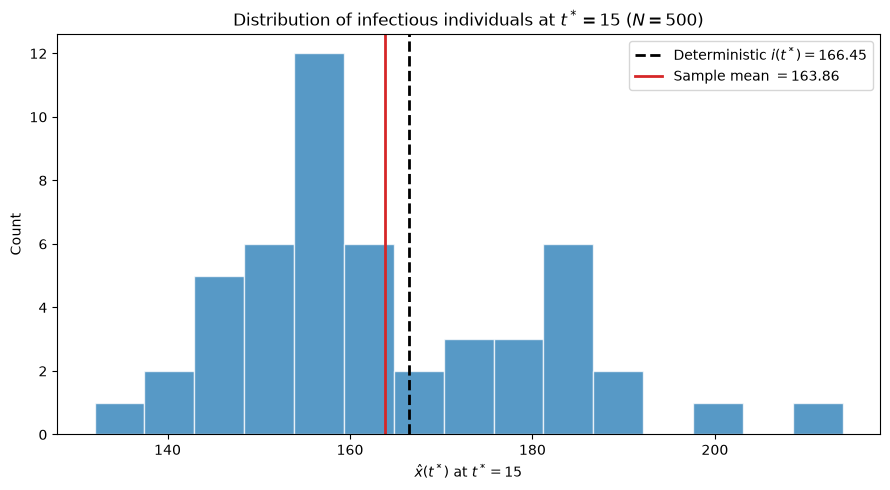

In [20]:
# Plot the histogram and mark the deterministic value and sample mean:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(samples_500, bins=15, color='tab:blue', alpha=0.75, edgecolor='white')
ax.axvline(
    i_star_500, color='black', linestyle='--', linewidth=2,
    label=fr'Deterministic $i(t^*)={i_star_500:.2f}$'
)
ax.axvline(
    mean_500, color='tab:red', linewidth=2,
    label=fr'Sample mean $={mean_500:.2f}$'
)
ax.set(
    xlabel=fr'$\hat{{x}}(t^*)$ at $t^*={t_star:g}$',
    ylabel='Count',
    title='Distribution of infectious individuals at $t^*=15$ ($N=500$)'
)
ax.legend()
plt.tight_layout()
plt.show()

For $N=500$, the histogram is centered near the deterministic value, but it shows visible stochastic variation across the 50 trajectories.

The sample mean is $163.86$, compared with the deterministic value $i(t^*)=166.45$. The difference is $-2.59$, which is small compared with the sample standard deviation of $16.97$.

## A2.1(d) Repeat parts b and c for $N=5000$

With $N=5000$, the initial infectious count is $x(0)=N/10=5000/10=500$. The same seed (42) is used for reproducibility; the population size is changed while the model parameters remain the same.

In [21]:
# Set up and simulate the 50 trajectories for N=5000:
N_5000 = 5000
x0_5000 = N_5000 // 10
params_5000 = {'N': N_5000, 'alpha': alpha, 'beta': beta}
rng_5000 = np.random.default_rng(42)

trajectories_5000 = [
    gillespie(
        x0=x0_5000, T=T, rng=rng_5000,
        rates=sis_rates, deltas=sis_deltas, params=params_5000
    )
    for _ in range(50)
]

# Compute the deterministic reference for the larger population:
t_eval_5000 = np.sort(np.unique(np.r_[np.linspace(0.0, T, 1000), t_star]))
solution_5000 = solve_ivp(
    lambda t, i: beta * i * (N_5000 - i) / N_5000 - alpha * i,
    (0.0, T), [x0_5000], t_eval=t_eval_5000,
    rtol=1e-9, atol=1e-11
)

samples_5000 = np.array([
    sample_at_time(times, states, t_star)
    for times, states in trajectories_5000
])
i_star_5000 = float(np.interp(t_star, solution_5000.t, solution_5000.y[0]))
mean_5000 = samples_5000.mean()
std_5000 = samples_5000.std(ddof=1)

print(f'N = {N_5000}, t* = {t_star:g}')
print(f'Sample mean = {mean_5000:.2f}')
print(f'Sample standard deviation = {std_5000:.2f}')
print(f'Deterministic i(t*) = {i_star_5000:.2f}')
print(f'Mean - deterministic = {mean_5000 - i_star_5000:+.2f}')

N = 5000, t* = 15
Sample mean = 1665.42
Sample standard deviation = 59.40
Deterministic i(t*) = 1664.52
Mean - deterministic = +0.90


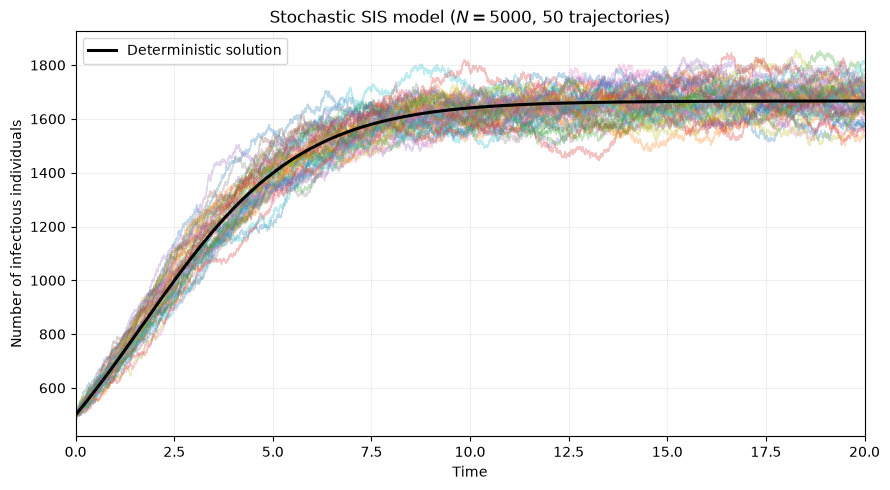

In [22]:
# Plot the N=5000 stochastic trajectories with the deterministic solution:
fig, ax = plt.subplots(figsize=(9, 5))
for times, states in trajectories_5000:
    ax.step(times, states, where='post', alpha=0.28, linewidth=0.9)

ax.plot(
    solution_5000.t, solution_5000.y[0], color='black', linewidth=2.2,
    label='Deterministic solution'
)
ax.set(
    xlabel='Time',
    ylabel='Number of infectious individuals',
    title='Stochastic SIS model ($N=5000$, 50 trajectories)'
)
ax.set_xlim(0, T)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

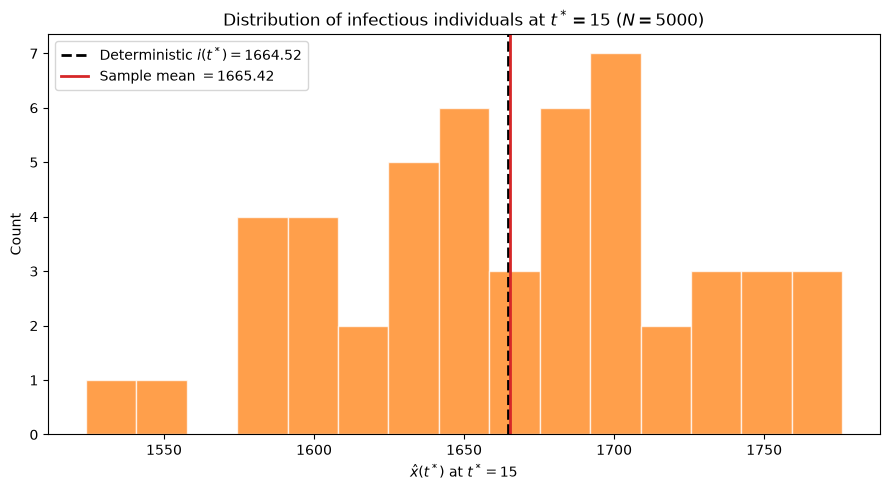

In [23]:
# Plot the N=5000 sample histogram and mark the deterministic value and sample mean:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(samples_5000, bins=15, color='tab:orange', alpha=0.75, edgecolor='white')
ax.axvline(
    i_star_5000, color='black', linestyle='--', linewidth=2,
    label=fr'Deterministic $i(t^*)={i_star_5000:.2f}$'
)
ax.axvline(
    mean_5000, color='tab:red', linewidth=2,
    label=fr'Sample mean $={mean_5000:.2f}$'
)
ax.set(
    xlabel=fr'$\hat{{x}}(t^*)$ at $t^*={t_star:g}$',
    ylabel='Count',
    title='Distribution of infectious individuals at $t^*=15$ ($N=5000$)'
)
ax.legend()
plt.tight_layout()
plt.show()

For $N=5000$, the sample mean is $1665.42$, compared with the deterministic value $i(t^*)=1664.52$. The difference is $+0.90$, which is small compared with the sample standard deviation of $59.40$.

### Rescaled samples

The raw standard deviation is larger for $N=5000$ because the population scale is larger. To compare relative fluctuations, rescale each sample by its deterministic value $i(t^*)$.

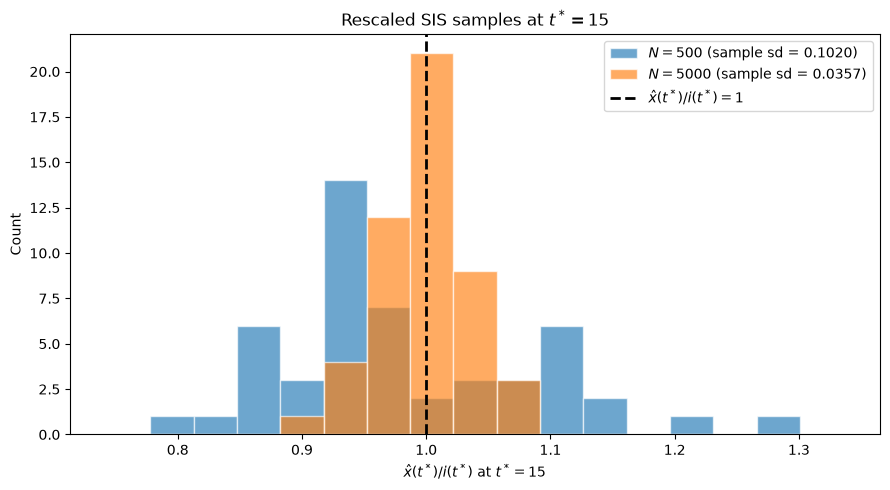

Rescaled sample standard deviations:
N = 500: 0.1020
N = 5000: 0.0357
Rescaled range: 0.793 to 1.286


In [24]:
# Rescale both samples and compare their relative spread in one histogram.
rescaled_500 = samples_500 / i_star_500
rescaled_5000 = samples_5000 / i_star_5000
rescaled_all = np.concatenate((rescaled_500, rescaled_5000))

fig, ax = plt.subplots(figsize=(9, 5))
lower = min(0.75, float(rescaled_all.min()) - 0.05)
upper = max(1.25, float(rescaled_all.max()) + 0.05)
bins = np.linspace(lower, upper, 18).tolist()
ax.hist(
    rescaled_500, bins=bins, alpha=0.65, edgecolor='white',
    label=fr'$N=500$ (sample sd = {rescaled_500.std(ddof=1):.4f})'
)
ax.hist(
    rescaled_5000, bins=bins, alpha=0.65, edgecolor='white',
    label=fr'$N=5000$ (sample sd = {rescaled_5000.std(ddof=1):.4f})'
)
ax.axvline(
    1.0, color='black', linestyle='--', linewidth=2,
    label=r'$\hat{x}(t^*)/i(t^*)=1$'
)
ax.set(
    xlabel=fr'$\hat{{x}}(t^*)/i(t^*)$ at $t^*={t_star:g}$',
    ylabel='Count',
    title='Rescaled SIS samples at $t^*=15$'
)
ax.legend()
plt.tight_layout()
plt.show()

print('Rescaled sample standard deviations:')
print(f'N = 500: {rescaled_500.std(ddof=1):.4f}')
print(f'N = 5000: {rescaled_5000.std(ddof=1):.4f}')
print(f'Rescaled range: {rescaled_all.min():.3f} to {rescaled_all.max():.3f}')

## Discussion

As mentioned above, at $t^*=15$, the deterministic values are $i(t^*)=166.45$ for $N=500$ and $i(t^*)=1664.52$ for $N=5000$. The sample means are $163.86$ and $1665.42$, respectively, so both remain close to the deterministic predictions. 

Although the raw standard deviation increases with population size, the relative spread decreases: it is about 0.1020 for $N=500$ and 0.0357 for $N=5000$. The rescaled histogram therefore concentrates more tightly around 1 as $N$ grows, supporting agreement between the stochastic and deterministic models in the large-population limit.